# Analisis dan Prediksi Overall Rating Pemain EA SPORTS FC 27 Menggunakan Algoritma Regresi


## 1. Memuat library dan data

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("players.csv")
print("Shape awal:", df.shape)
df.head()

Shape awal: (19789, 60)


,player_id,common_name,first_name,last_name,overall_rating,position,alternate_positions,club,league,nationality,...,defending_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,edition,snapshot_date
0,227203,Alexia Putellas,Alexia,Putellas Segura,91,CM,CAM ST,London City,Barclays WSL,Spain,...,60,82,64,15,17,11,15,10,fc27,2026-09-12
1,231747,NaN,Kylian,Mbappé,91,ST,LW,Real Madrid,LALIGA EA SPORTS,France,...,15,34,24,13,5,7,11,6,fc27,2026-09-12
2,239085,NaN,Erling,Haaland,91,ST,NaN,Manchester City,Premier League,Norway,...,42,47,33,7,14,13,11,7,fc27,2026-09-12
3,192119,NaN,Thibaut,Courtois,90,GK,NaN,Real Madrid,LALIGA EA SPORTS,Belgium,...,20,18,16,87,89,78,90,90,fc27,2026-09-12
4,202126,NaN,Harry,Kane,90,ST,NaN,FC Bayern München,Bundesliga,England,...,46,44,42,8,10,11,14,11,fc27,2026-09-12


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19789 entries, 0 to 19788
Data columns (total 60 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   player_id                   19789 non-null  int64  
 1   common_name                 2879 non-null   str    
 2   first_name                  19789 non-null  str    
 3   last_name                   19789 non-null  str    
 4   overall_rating              19789 non-null  int64  
 5   position                    19789 non-null  str    
 6   alternate_positions         12896 non-null  str    
 7   club                        19789 non-null  str    
 8   league                      19789 non-null  str    
 9   nationality                 19789 non-null  str    
 10  gender                      19789 non-null  str    
 11  preferred_foot              19789 non-null  str    
 12  skill_moves                 19789 non-null  int64  
 13  weak_foot                   19789 non-null

## 2. Pembersihan dan persiapan data

Pada tahap ini, data diperiksa dan disiapkan sebelum dianalisis:
- Memeriksa data duplikat berdasarkan `player_id`.
- Menghapus kolom yang seluruh nilainya kosong (`height_cm`, `weight_kg`) serta kolom dengan satu nilai yang sama (`edition`, `snapshot_date`).
- Mengisi nilai kosong pada `playstyles` dan `alternate_positions` dengan string kosong. Dalam data ini, nilai kosong menunjukkan bahwa pemain tidak memiliki playstyle atau posisi alternatif yang tercatat.
- Membuat fitur tambahan: `age`, `n_playstyles`, `n_playstyle_plus`, `n_alt_pos`, `pos_group`, dan `is_gk`.

In [4]:
print("Missing per kolom (yang ada missing):")
print(df.isna().sum()[df.isna().sum() > 0])
print("Duplikat baris:", df.duplicated().sum(), "| duplikat player_id:", df.player_id.duplicated().sum())

Missing per kolom (yang ada missing):
common_name            16910
alternate_positions     6893
height_cm              19789
weight_kg              19789
playstyles             11738
dtype: int64
Duplikat baris: 0 | duplikat player_id: 0


In [5]:
df = df.drop_duplicates("player_id")

kosong = [c for c in df.columns if df[c].isna().all()]
print("Kolom kosong total:", kosong)
df = df.drop(columns=kosong + ["edition", "snapshot_date"])

df["playstyles"] = df["playstyles"].fillna("")
df["alternate_positions"] = df["alternate_positions"].fillna("")

df["birthdate"] = pd.to_datetime(df["birthdate"], errors="coerce")
print("Birthdate tidak valid:", df.birthdate.isna().sum())

# Feature engineering
df["age"] = (pd.Timestamp("2026-09-12") - df["birthdate"]).dt.days / 365.25
df["n_playstyles"] = df.playstyles.apply(lambda s: len([x for x in s.split(",") if x.strip()]))
df["n_playstyle_plus"] = df.playstyles.apply(lambda s: sum(x.strip().endswith("+") for x in s.split(",")))
df["n_alt_pos"] = df.alternate_positions.apply(lambda s: len(s.split()))
df["is_gk"] = (df.position == "GK").astype(int)
pos_map = {"GK":"GK","CB":"DEF","LB":"DEF","RB":"DEF","LWB":"DEF","RWB":"DEF",
           "CDM":"MID","CM":"MID","CAM":"MID","LM":"MID","RM":"MID"}
df["pos_group"] = df.position.map(pos_map).fillna("FWD")

print("Shape setelah cleaning:", df.shape)
print("Usia min/median/max:", round(df.age.min(),1), round(df.age.median(),1), round(df.age.max(),1))

Kolom kosong total: ['height_cm', 'weight_kg']
Birthdate tidak valid: 0
Shape setelah cleaning: (19789, 62)
Usia min/median/max: 17.0 25.5 42.9


In [6]:
# Validasi: semua atribut harus dalam rentang 1-99 dan tidak ada missing di fitur numerik
num_cols = df.select_dtypes("number").columns
atribut = [c for c in num_cols if c not in ("player_id","age","n_playstyles","n_playstyle_plus","n_alt_pos","is_gk","skill_moves","weak_foot")]
print("Atribut di luar 1-99:", [c for c in atribut if df[c].min() < 1 or df[c].max() > 99])
print("Missing di fitur numerik:", int(df[num_cols].isna().sum().sum()))

Atribut di luar 1-99: []
Missing di fitur numerik: 0


## 3. Eksplorasi data (EDA)

In [7]:
y = df["overall_rating"]
y.describe()

count    19789.000000
mean        66.723281
std          6.959486
min         47.000000
25%         62.000000
50%         67.000000
75%         71.000000
max         91.000000
Name: overall_rating, dtype: float64

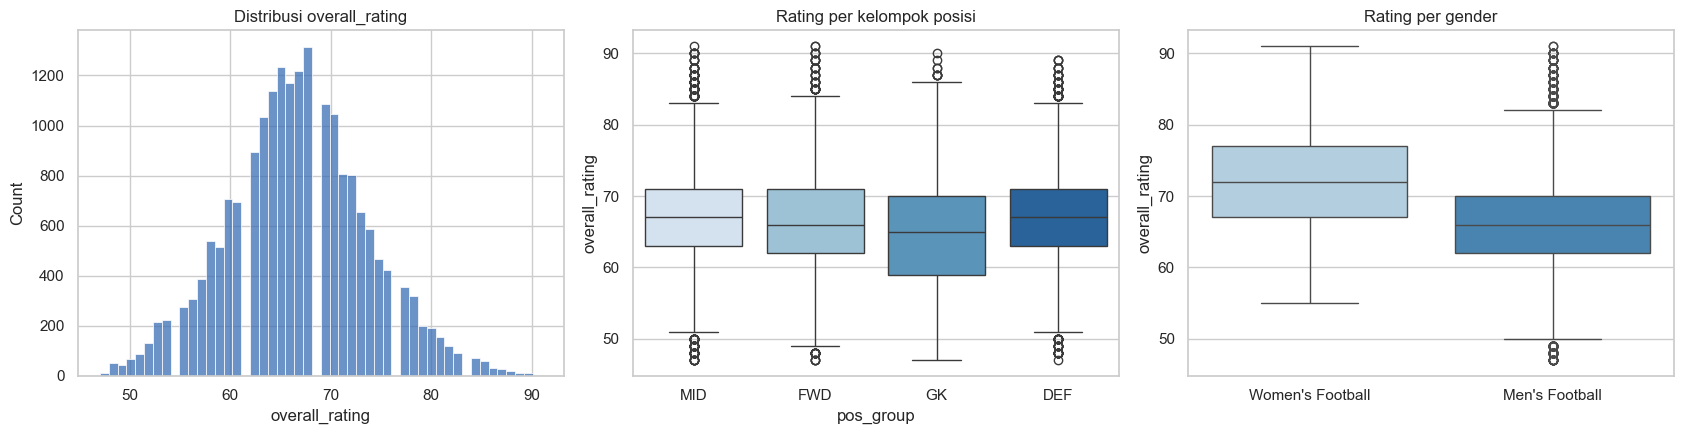

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(y, bins=50, ax=ax[0], color="#3b6fb6"); ax[0].set_title("Distribusi overall_rating")
sns.boxplot(data=df, x="pos_group", y="overall_rating", ax=ax[1], palette="Blues"); ax[1].set_title("Rating per kelompok posisi")
sns.boxplot(data=df, x="gender", y="overall_rating", ax=ax[2], palette="Blues"); ax[2].set_title("Rating per gender"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretasi:** Distribusi rating mendekati normal (skew ? 0,12), sehingga target tidak perlu ditransformasi. Rata-rata pemain perempuan pada data ini lebih tinggi. Namun, jumlah dan komposisi kelompoknya berbeda?termasuk liga yang tercakup?jadi perbedaan tersebut tidak dapat digunakan untuk menyimpulkan bahwa gender menyebabkan rating lebih tinggi.

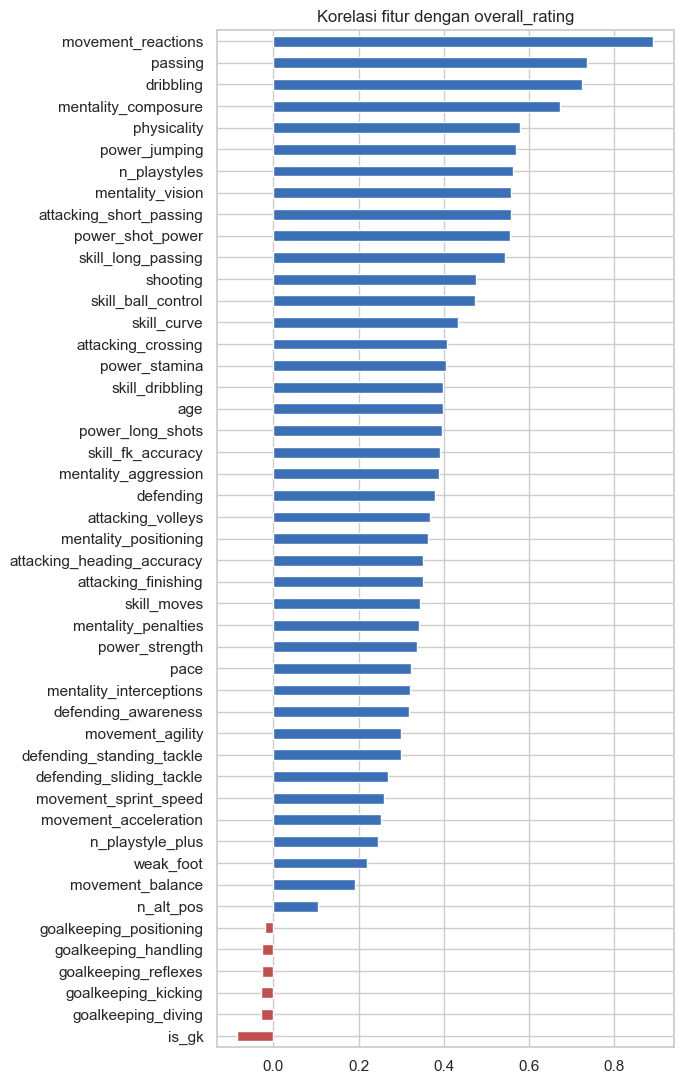

mentality_vision       0.556730
n_playstyles           0.561588
power_jumping          0.567949
physicality            0.577726
mentality_composure    0.671813
dribbling              0.723359
passing                0.735695
movement_reactions     0.890866
Name: overall_rating, dtype: float64


In [9]:
feat_num = [c for c in num_cols if c not in ("player_id","overall_rating")]
corr = df[feat_num + ["overall_rating"]].corr()["overall_rating"].drop("overall_rating").sort_values()
plt.figure(figsize=(7, 11))
corr.plot.barh(color=np.where(corr > 0, "#3b6fb6", "#c0504d"))
plt.title("Korelasi fitur dengan overall_rating"); plt.tight_layout(); plt.show()
print(corr.tail(8))

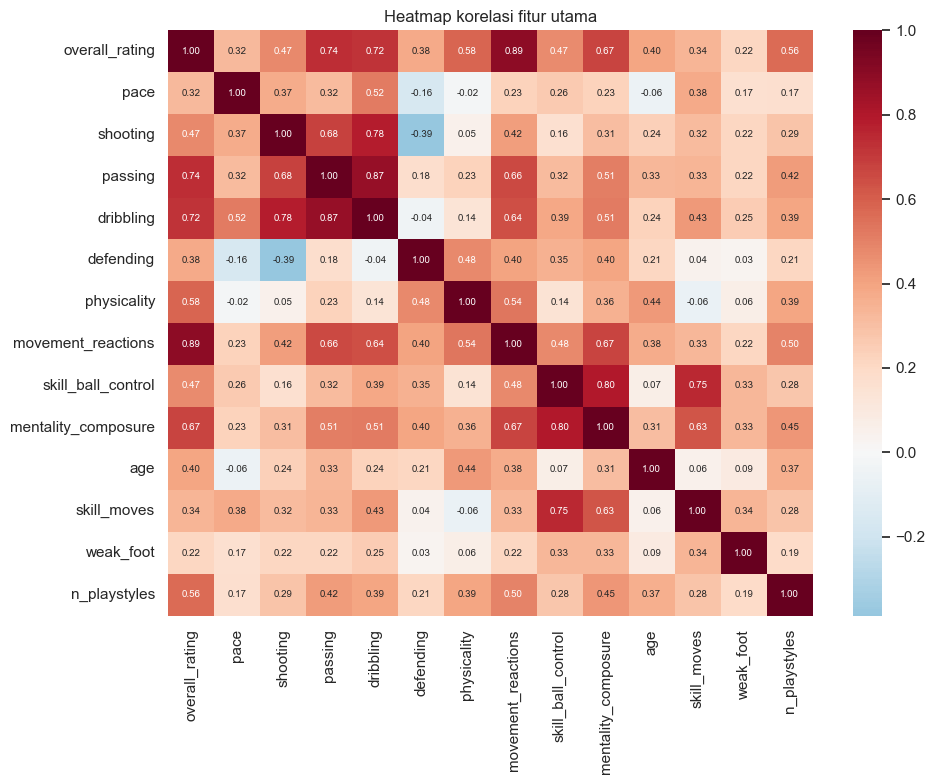

In [10]:
core = ["overall_rating","pace","shooting","passing","dribbling","defending","physicality",
        "movement_reactions","skill_ball_control","mentality_composure","age","skill_moves","weak_foot","n_playstyles"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[core].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size":7})
plt.title("Heatmap korelasi fitur utama"); plt.tight_layout(); plt.show()

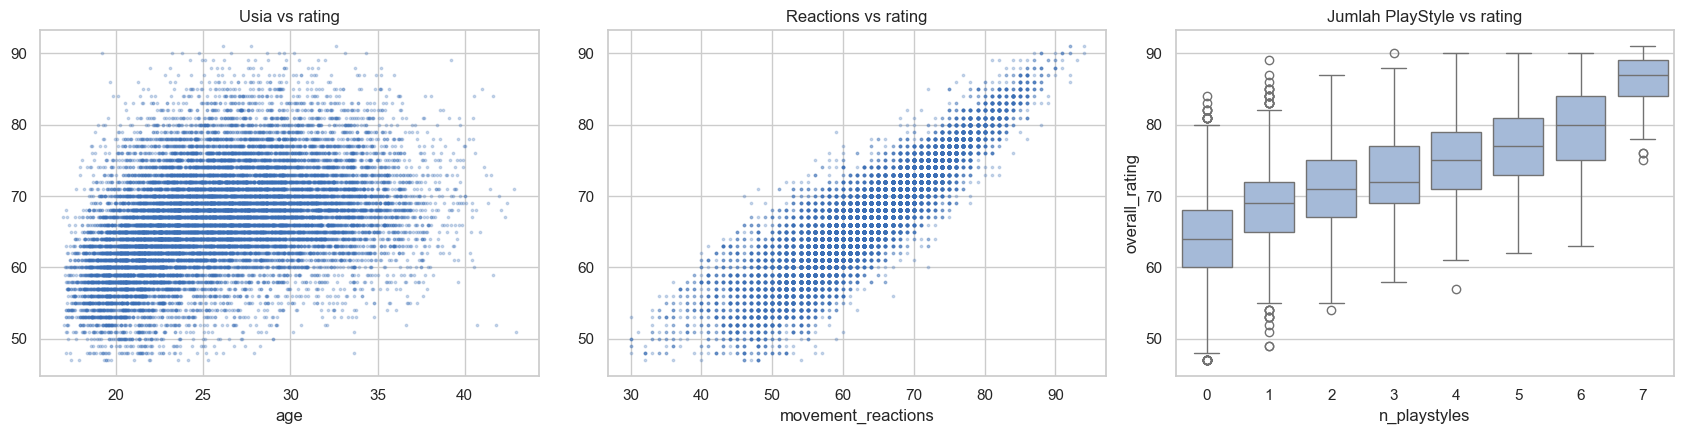

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(df.age, y, s=3, alpha=.25, color="#3b6fb6"); ax[0].set_title("Usia vs rating"); ax[0].set_xlabel("age")
ax[1].scatter(df.movement_reactions, y, s=3, alpha=.25, color="#3b6fb6"); ax[1].set_title("Reactions vs rating"); ax[1].set_xlabel("movement_reactions")
sns.boxplot(data=df, x="n_playstyles", y="overall_rating", ax=ax[2], color="#9db9e0"); ax[2].set_title("Jumlah PlayStyle vs rating")
plt.tight_layout(); plt.show()

**Interpretasi:** Dari atribut yang dibandingkan, `movement_reactions` memiliki korelasi paling kuat dengan rating (r ? 0,89). Korelasi atribut kiper mendekati nol; atribut tersebut hanya relevan untuk sekitar 11% pemain yang berposisi sebagai kiper.

## 4. EDA lanjutan: outlier, multikolinearitas, dan kategori

In [12]:
q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
n_out = ((y < q1 - 1.5*iqr) | (y > q3 + 1.5*iqr)).sum()
print(f"Outlier target (IQR): {n_out} ({n_out/len(y):.2%}) | skewness: {y.skew():.2f}")

Outlier target (IQR): 229 (1.16%) | skewness: 0.12


In [13]:
# Multikolinearitas: pasangan fitur dengan korelasi absolut tertinggi
mask = np.triu(np.ones((len(feat_num), len(feat_num))), 1).astype(bool)
hc = df[feat_num].corr().abs().where(mask).stack().sort_values(ascending=False)
hc.head(6)

defending_standing_tackle  defending_sliding_tackle    0.977954
goalkeeping_diving         is_gk                       0.977203
goalkeeping_reflexes       is_gk                       0.976959
goalkeeping_handling       is_gk                       0.976128
goalkeeping_diving         goalkeeping_reflexes        0.974901
goalkeeping_kicking        is_gk                       0.974873
dtype: float64

In [14]:
print(df.groupby("gender").overall_rating.agg(["mean","std","count"]).round(2))
print()
print(df.groupby("league").overall_rating.agg(["mean","count"]).query("count >= 100")
        .sort_values("mean", ascending=False).head(8).round(2))

                   mean   std  count
gender                              
Men's Football    66.18  6.73  17849
Women's Football  71.74  6.99   1940

                   mean  count
league                        
Premier League    75.20    612
Barclays WSL      73.87    347
LALIGA EA SPORTS  73.59    548
NWSL              73.12    395
Serie A Enilive   72.92    578
Hellas Liga       72.25    123
Liga F Moeve      72.24    301
Bundesliga        71.95    548


**Interpretasi:** Outlier mencakup sekitar 1% data dan mewakili pemain dengan rating tinggi, sehingga tetap dipertahankan. Beberapa fitur memiliki korelasi yang sangat tinggi, misalnya `standing_tackle` dan `sliding_tackle` (? 0,98). Hal ini umumnya tidak menjadi kendala utama bagi model berbasis pohon, tetapi dapat membuat koefisien model linear sulit ditafsirkan. Karena itu, kontribusi fitur juga diperiksa dengan *permutation importance*.

## 5. Membagi data train dan test

Data dibagi menjadi 80% untuk train dan 20% untuk test dengan `random_state=42`. Pembagian dilakukan secara *stratified* berdasarkan kelompok posisi agar proporsi kiper, bek, gelandang, dan penyerang serupa pada kedua set.

In [15]:
cat_cols = ["preferred_foot", "gender", "pos_group", "position"]
num_feats = list(feat_num)
X = df[num_feats + cat_cols]

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df.pos_group)
print("Train:", Xtr.shape, "| Test:", Xte.shape)

Train: (15831, 51) | Test: (3958, 51)


## 6. Pemodelan

Seluruh preprocessing disusun di dalam `Pipeline`. Dengan demikian, *scaler* dan *encoder* dipelajari dari data train saja, sehingga informasi dari data test tidak ikut digunakan saat pelatihan.

Model yang dibandingkan adalah Linear Regression sebagai baseline, Ridge, Random Forest, dan Hist Gradient Boosting.

In [16]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, random_state=RANDOM_STATE),
}

rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("m", m)]).fit(Xtr, ytr)
    fitted[name] = pipe
    ptr, pte = pipe.predict(Xtr), pipe.predict(Xte)
    cv = cross_val_score(Pipeline([("pre", pre), ("m", m)]), Xtr, ytr, cv=5, scoring="r2").mean()
    rows.append({
        "Model": name,
        "MAE_train": mean_absolute_error(ytr, ptr), "MSE_train": mean_squared_error(ytr, ptr), "R2_train": r2_score(ytr, ptr),
        "MAE_test": mean_absolute_error(yte, pte), "MSE_test": mean_squared_error(yte, pte),
        "RMSE_test": mean_squared_error(yte, pte) ** 0.5, "R2_test": r2_score(yte, pte), "R2_CV5": cv,
    })

hasil = pd.DataFrame(rows).round(4)
hasil

,Model,MAE_train,MSE_train,R2_train,MAE_test,MSE_test,RMSE_test,R2_test,R2_CV5
0,Linear Regression,1.3328,2.9460,0.9394,1.3007,2.7961,1.6722,0.9412,0.9389
1,Ridge (alpha=10),1.3329,2.9467,0.9394,1.2999,2.7926,1.6711,0.9413,0.9389
2,Random Forest,0.3214,0.1953,0.9960,0.7707,1.0771,1.0378,0.9774,0.9770
3,Hist Gradient Boosting,0.3786,0.2379,0.9951,0.5351,0.5022,0.7086,0.9894,0.9889


## 7. Evaluasi model

- **MAE** menunjukkan rata-rata selisih absolut antara prediksi dan rating aktual, dalam poin rating.
- **MSE** menghitung rata-rata kuadrat selisih prediksi. **RMSE** adalah akar MSE dan kembali dinyatakan dalam poin rating.
- **R?** menunjukkan seberapa besar variasi rating yang dapat dijelaskan model; nilai 1 berarti prediksi sempurna.

Hasil train dan test dibandingkan untuk melihat indikasi *overfitting*. Nilai R? dari validasi silang (CV) juga digunakan untuk menilai kestabilan hasil.

In [17]:
hasil[["Model","MAE_test","MSE_test","RMSE_test","R2_test"]].sort_values("MSE_test")

,Model,MAE_test,MSE_test,RMSE_test,R2_test
3,Hist Gradient Boosting,0.5351,0.5022,0.7086,0.9894
2,Random Forest,0.7707,1.0771,1.0378,0.9774
1,Ridge (alpha=10),1.2999,2.7926,1.6711,0.9413
0,Linear Regression,1.3007,2.7961,1.6722,0.9412


Model terbaik: Hist Gradient Boosting


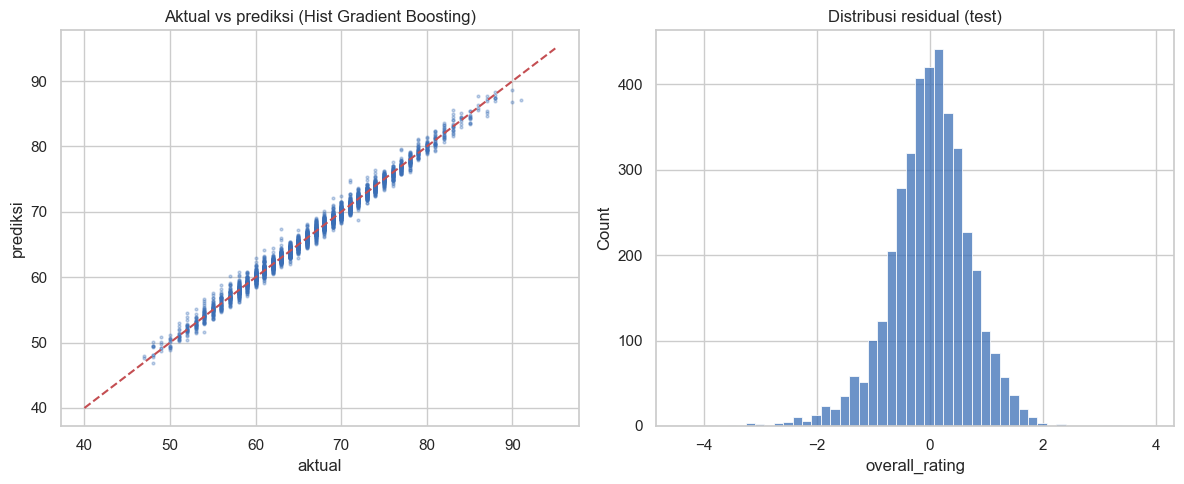

In [18]:
best = hasil.sort_values("MSE_test").iloc[0].Model
bp = fitted[best]
pred = bp.predict(Xte)
print("Model terbaik:", best)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(yte, pred, s=4, alpha=.3, color="#3b6fb6"); ax[0].plot([40, 95], [40, 95], "r--")
ax[0].set_title(f"Aktual vs prediksi ({best})"); ax[0].set_xlabel("aktual"); ax[0].set_ylabel("prediksi")
sns.histplot(yte - pred, bins=50, ax=ax[1], color="#3b6fb6"); ax[1].set_title("Distribusi residual (test)")
plt.tight_layout(); plt.show()

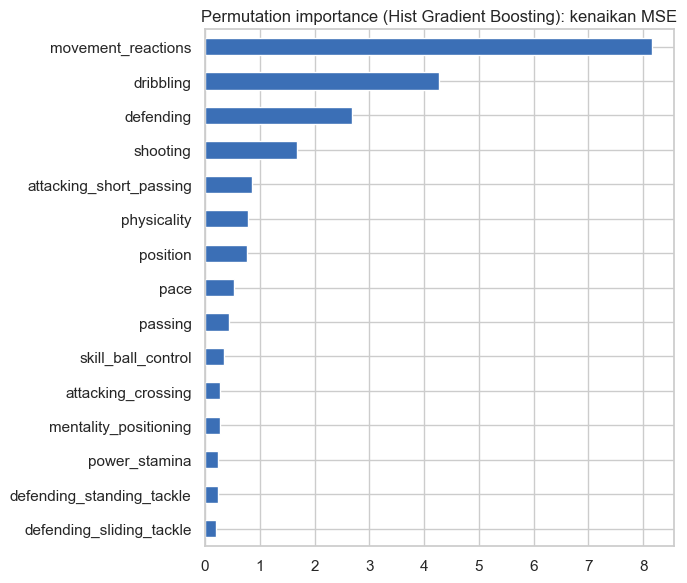

In [19]:
pi = permutation_importance(bp, Xte, yte, n_repeats=5, random_state=RANDOM_STATE,
                            scoring="neg_mean_squared_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values().tail(15)
plt.figure(figsize=(7, 6)); imp.plot.barh(color="#3b6fb6")
plt.title(f"Permutation importance ({best}): kenaikan MSE"); plt.tight_layout(); plt.show()

## 8. Kesimpulan

Pada data test, Hist Gradient Boosting memberikan hasil terbaik di antara model yang diuji, dengan MAE sekitar 0,54, MSE 0,51 (RMSE 0,71), dan R? 0,989. Nilai R? validasi silang 5-fold mendekati nilai test, sementara selisih performa train dan test relatif kecil. Hasil ini menunjukkan adanya indikasi *overfitting* ringan.

Model non-linear mengungguli model linear, yang memperoleh R? sekitar 0,941. Ini menunjukkan bahwa hubungan antara atribut dan rating pada data ini tidak sepenuhnya linear, dan dapat berbeda menurut posisi pemain. Fitur yang paling berkontribusi dalam analisis ini adalah `movement_reactions`, `dribbling`, `defending`, dan `shooting`.

**Keterbatasan dan pengembangan selanjutnya:**
1. Beberapa atribut, seperti `pace` dan `shooting`, juga digunakan dalam perhitungan rating oleh EA. Karena itu, model mungkin mempelajari kembali sebagian hubungan yang sudah tercermin dalam rating. Analisis lanjutan dapat menguji model tanpa enam atribut facet kartu.
2. Data yang digunakan hanya berasal dari satu snapshot, tertanggal 12 September 2026.
3. Hyperparameter model belum dituning.
4. Model belum dibuat secara terpisah untuk setiap posisi.